# 03 - TF-IDF Evaluation & Comparison

In [1]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import joblib
import json
import os
import sys
from IPython.display import display
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, hamming_loss
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../../"))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import multilabel_confusion_matrix


## 1. Load Data, Model and Thresholds

In [2]:
aspect_cols = ['food', 'service', 'price', 'ambiance', 'miscellaneous']

X_test_tfidf = sp.load_npz(os.path.join(PROJECT_ROOT, "outputs", "TF-IDF", "X_test_tfidf.npz"))
y_test = pd.read_csv(os.path.join(PROJECT_ROOT, "outputs", "TF-IDF", "y_test.csv"))

classifiers_dir = os.path.join(PROJECT_ROOT, "models", "TF-IDF", "classifiers")
model = joblib.load(os.path.join(classifiers_dir, "tfidf_ovr_logreg.joblib"))

with open(os.path.join(classifiers_dir, "tfidf_metadata.json"), "r") as f:
    metadata = json.load(f)
    
optimal_thresholds = metadata['thresholds']
print("Loaded Thresholds:", optimal_thresholds)


Loaded Thresholds: {'food': 0.1, 'service': 0.5, 'price': 0.5, 'ambiance': 0.5, 'miscellaneous': 0.5}


## 2. Generate Predictions (with fallback logic)

In [3]:
y_test_prob = model.predict_proba(X_test_tfidf)
y_test_pred = np.zeros_like(y_test_prob)

for i, col in enumerate(aspect_cols):
    y_test_pred[:, i] = (y_test_prob[:, i] >= optimal_thresholds[col]).astype(int)

# Fallback: if no class is predicted, pick the one with max probability
empty_rows = np.flatnonzero(y_test_pred.sum(axis=1) == 0)
for row in empty_rows:
    y_test_pred[row, np.argmax(y_test_prob[row])] = 1


## 3. Evaluation Metrics

In [4]:
print("Classification Report (TF-IDF):\n")
report = classification_report(y_test, y_test_pred, target_names=aspect_cols, zero_division=0)
print(report)

metrics_dict = {
    'F1 Micro': f1_score(y_test, y_test_pred, average='micro', zero_division=0),
    'F1 Macro': f1_score(y_test, y_test_pred, average='macro', zero_division=0),
    'F1 Samples': f1_score(y_test, y_test_pred, average='samples', zero_division=0),
    'Precision Micro': precision_score(y_test, y_test_pred, average='micro', zero_division=0),
    'Recall Micro': recall_score(y_test, y_test_pred, average='micro', zero_division=0),
    'Hamming Loss': hamming_loss(y_test, y_test_pred)
}

metrics_df = pd.DataFrame([metrics_dict]).T.reset_index()
metrics_df.columns = ['Metric', 'TF-IDF Value']
display(metrics_df)

# Save metrics
metrics_df.to_csv(os.path.join(PROJECT_ROOT, "outputs", "TF-IDF", "tfidf_evaluation_metrics.csv"), index=False)


Classification Report (TF-IDF):

               precision    recall  f1-score   support

         food       0.84      1.00      0.91       134
      service       0.85      0.81      0.83        42
        price       0.91      0.93      0.92        85
     ambiance       0.71      0.83      0.76        35
miscellaneous       1.00      0.29      0.44        14

    micro avg       0.84      0.90      0.87       310
    macro avg       0.86      0.77      0.77       310
 weighted avg       0.85      0.90      0.86       310
  samples avg       0.86      0.91      0.87       310



,Metric,TF-IDF Value
0,F1 Micro,0.872274
1,F1 Macro,0.773408
2,F1 Samples,0.870417
3,Precision Micro,0.843373
4,Recall Micro,0.903226
5,Hamming Loss,0.102500


### Confusion Matrices
Plotting multilabel confusion matrices to show correct and incorrect predictions side-by-side for all aspects.

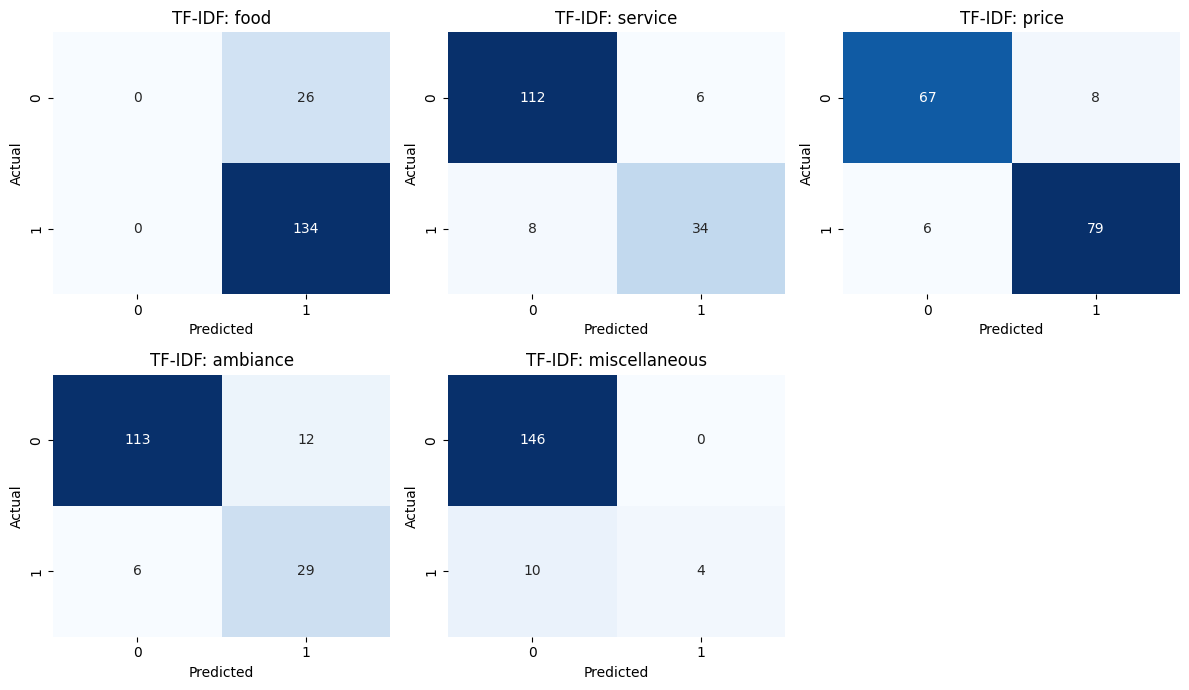

In [5]:
matrices = multilabel_confusion_matrix(y_test, y_test_pred)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for index, aspect in enumerate(aspect_cols):
    sns.heatmap(
        matrices[index],
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes.flat[index],
    )
    axes.flat[index].set_title(f"TF-IDF: {aspect}")
    axes.flat[index].set_xlabel("Predicted")
    axes.flat[index].set_ylabel("Actual")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


## 4. Error Analysis

In [6]:
# Load the raw text
split_data = np.load(os.path.join(PROJECT_ROOT, "outputs", "MPNet", "data_split.npz"))
test_idx = split_data['test_idx']
df = pd.read_csv(os.path.join(PROJECT_ROOT, "data", "Restaurant_ABSA_processed.csv"))
X_test_text = df.iloc[test_idx]['review_en'].values

def labels_to_text(row, aspect_cols):
    row = np.asarray(row).astype(bool)
    labels = np.array(aspect_cols)[row]
    return ', '.join(labels) if len(labels) > 0 else 'None'

results_df = pd.DataFrame({
    'review': X_test_text,
    'true_aspects': [labels_to_text(row, aspect_cols) for row in y_test.values],
    'predicted_aspects': [labels_to_text(row, aspect_cols) for row in y_test_pred]
})

misclassified_df = results_df[results_df['true_aspects'] != results_df['predicted_aspects']]
print(f"Total misclassified samples: {len(misclassified_df)} out of {len(results_df)}")

# Save misclassified
misclassified_df.to_csv(os.path.join(PROJECT_ROOT, "outputs", "TF-IDF", "tfidf_misclassified.csv"), index=False)
display(misclassified_df.head())

Total misclassified samples: 58 out of 160


,review,true_aspects,predicted_aspects
1,the restaurant is very clean and the ambience ...,ambiance,"food, ambiance"
3,from today it is my favorite restaurant becaus...,"service, price","food, service, price"
9,their kitchen is not very nice so people canno...,"food, ambiance",food
10,their service is great and food quality is good,"food, service","food, service, ambiance"
11,there is no extra decoration and the service i...,"service, ambiance","food, service"
